## SMS: Spam or Ham classifier using Naive Bayes

In [ ]:
import sys
import numpy
numpy.set_printoptions(threshold=sys.maxsize)
import pandas as pd
docs = pd.read_table('SMSSpamCollection+(1)', header=None, names=['Class', 'sms'])
import warnings
warnings.filterwarnings('ignore')

In [2]:
docs.shape

(5572, 2)

In [3]:
docs.head(11)

,Class,sms
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [4]:
docs["sms"].head()

0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: sms, dtype: object

In [5]:
#df.column_name.value_counts() - gives no. of unique inputs in that columns
docs["Class"].value_counts()

Class
ham     4825
spam     747
Name: count, dtype: int64

In [6]:
# mapping labels to 1 and 0
docs['label'] = docs.Class.map({'ham':0, 'spam':1})

In [7]:
docs.head()

,Class,sms,label
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [8]:
# generic modelling steps

In [9]:
X = docs.sms
y = docs.label
print(X.shape)
print(y.shape)

(5572,)
(5572,)


In [10]:
# splitting into test and train

from sklearn.model_selection  import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.30, random_state=1)

In [11]:
X_train.head()

4393                       what are your new years plans?
216     Finally the match heading towards draw as your...
4471    Lemme know when I can swing by and pick up, I'...
3889                   ok....take care.umma to you too...
5030    I'd like to tell you my deepest darkest fantas...
Name: sms, dtype: object

In [12]:
y_train.head()

4393    0
216     0
4471    0
3889    0
5030    1
Name: label, dtype: int64

In [ ]:
X_train.shape

(3900,)

In [14]:
X_test.shape

(1672,)

In [15]:
#CountVectorizer: converting text to vectors

In [16]:
from sklearn.feature_extraction.text import CountVectorizer
# list of text documents

data = ["The quick brown, fox  jumped OVER the lazy  dog."]
        #[1 1 1 1 1 1 1 2]- vector to the model, which represents the above data

# create the transformation
vectorizer_obj = CountVectorizer()

# tokenize and build vocab(all the unique words from the given data)
vectorizer_obj.fit(data)
#1-entire sentence is tokenized into words
#2-words are convertted to lowercase
#3-removes special characters (,.!)
#4-removes duplicate words
#5-gives a number to every unique word in alphabatical order of the words

print("Given Data:")
print(data)
print("-"*20)

# # returns and build vocab ie - unique words in the given text/document/data/corpus
print("Vocabulary:")

print(vectorizer_obj.vocabulary_)
print("-"*20)


# # # encode document
vector = vectorizer_obj.transform(data)
# # # # # # # summarize encoded vector
print(vector.shape)

print(type(vector))
print("-"*20)
print(vectorizer_obj.get_feature_names_out())
print(vector.toarray())


Given Data:
['The quick brown, fox  jumped OVER the lazy  dog.']
--------------------
Vocabulary:
{'the': 7, 'quick': 6, 'brown': 0, 'fox': 2, 'jumped': 3, 'over': 5, 'lazy': 4, 'dog': 1}
--------------------
(1, 8)
<class 'scipy.sparse._csr.csr_matrix'>
--------------------
['brown' 'dog' 'fox' 'jumped' 'lazy' 'over' 'quick' 'the']
[[1 1 1 1 1 1 1 2]]


In [17]:
data1 = ["the king  brown fox "]

# # # encode document
# vectorizer_obj.fit(data1)

vector = vectorizer_obj.transform(data1)

# # # # summarize encoded vector
print(vector.shape)

# # # print(type(vector))
print(vector.toarray())
print(vectorizer_obj.get_feature_names_out())


(1, 8)
[[1 0 1 0 0 0 0 1]]
['brown' 'dog' 'fox' 'jumped' 'lazy' 'over' 'quick' 'the']


In [18]:
text2 = ["the dog and lazy the"]


vector = vectorizer_obj.transform(text2)
print(vector.toarray())
vectorizer_obj.get_feature_names_out()


[[0 1 0 0 1 0 0 2]]


array(['brown', 'dog', 'fox', 'jumped', 'lazy', 'over', 'quick', 'the'],
      dtype=object)

In [19]:
import nltk
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [20]:
from nltk.corpus import stopwords
stopwords = set(stopwords.words('english'))
print(stopwords)
print(len(stopwords))
type(stopwords)

{'which', 'same', 'yours', 'against', 'under', 'are', 'hadn', 'other', 'didn', 'couldn', 'most', "couldn't", 'after', 'if', 'your', 'o', 'or', 'needn', "doesn't", 'before', "haven't", "mightn't", "it's", 'being', 'not', "they're", "won't", "he's", 'by', 'out', 'what', "you'll", "didn't", "she'd", 'further', "shouldn't", "they'll", 'while', 'wasn', 'himself', 'more', "mustn't", 'between', 'how', 'she', 'is', 'her', 'through', 'and', 'can', 'it', 'few', 'did', 'the', 'my', "isn't", 'just', 'whom', "they'd", 'y', 'as', "he'll", "i'm", 'i', "they've", 'yourself', 'who', 'won', 'where', "hadn't", 'yourselves', "needn't", 'haven', 'until', "we've", "it'd", 'weren', "you've", 'then', "she'll", 't', 'aren', 'this', 'was', 'having', 'you', 'at', 'wouldn', 'above', 'with', 'has', 'should', "we're", "he'd", 'am', 'doing', 'all', 'now', 'down', 'those', 'to', 'off', "i've", 'myself', "wasn't", "we'll", 'shan', 'doesn', 'no', 'does', 'only', 'own', 'here', 'them', 'our', 'ain', 'but', 'have', 'on',

set

In [21]:
#example 
# "congtrs on the certification" --original text
#this will have vector size as 4....4 features

# "congtrs certification" -- after removing stopwords
# only 2 features or vectors size 2


In [22]:
X_train.head()

4393                       what are your new years plans?
216     Finally the match heading towards draw as your...
4471    Lemme know when I can swing by and pick up, I'...
3889                   ok....take care.umma to you too...
5030    I'd like to tell you my deepest darkest fantas...
Name: sms, dtype: object

In [23]:
X_test.head(30)

1078                         Yep, by the pretty sculpture
4028        Yes, princess. Are you going to make me moan?
958                            Welp apparently he retired
4642                                              Havent.
4674    I forgot 2 ask ü all smth.. There's a card on ...
5461    Ok i thk i got it. Then u wan me 2 come now or...
4210    I want kfc its Tuesday. Only buy 2 meals ONLY ...
4216                           No dear i was sleeping :-P
1603                            Ok pa. Nothing problem:-)
1504                      Ill be there on  &lt;#&gt;  ok.
1783    My uncles in Atlanta. Wish you guys a great se...
3465                                             My phone
5534                         Ok which your another number
4267    The greatest test of courage on earth is to be...
2498    Dai what this da.. Can i send my resume to thi...
4259                        I am late. I will be there at
147     FreeMsg Why haven't you replied to my text? I'...
141           

In [24]:
from sklearn.feature_extraction.text import CountVectorizer
#     and or the - stop words in english
# vectorising the text
vect = CountVectorizer(stop_words='english')

In [25]:
vect.fit(X_train)

CountVectorizer(stop_words='english')

In [26]:
vect.vocabulary_

{'new': 4272,
 'years': 6855,
 'plans': 4682,
 'finally': 2550,
 'match': 3930,
 'heading': 3018,
 'draw': 2202,
 'prediction': 4801,
 'lemme': 3650,
 'know': 3548,
 'swing': 5957,
 'pick': 4644,
 'free': 2663,
 'basically': 1119,
 'time': 6163,
 'semester': 5369,
 'ok': 4406,
 'care': 1485,
 'umma': 6353,
 'like': 3685,
 'tell': 6043,
 'deepest': 2000,
 'darkest': 1949,
 'fantasies': 2478,
 '09094646631': 222,
 'just': 3472,
 '60p': 538,
 'min': 4022,
 'stop': 5804,
 'texts': 6083,
 '08712460324': 103,
 'nat': 4218,
 'rate': 4985,
 'lmao': 3732,
 'fish': 2566,
 'memory': 3984,
 'need': 4243,
 'yahoo': 6841,
 'boys': 1324,
 'bring': 1354,
 'perf': 4592,
 'legal': 3644,
 'hiya': 3083,
 'comin': 1722,
 'bristol': 1358,
 'st': 5740,
 'week': 6637,
 'april': 940,
 'les': 3656,
 'got': 2862,
 'rudi': 5234,
 'yrs': 6882,
 'eve': 2383,
 'snoring': 5603,
 'drunk': 2226,
 'bak': 1092,
 'college': 1710,
 'work': 6769,
 'sends': 5374,
 'ink': 3289,
 'bath': 1123,
 'wamma': 6574,
 'laid': 3581,
 '

In [27]:
vect.get_feature_names_out()

array(['00', '000', '008704050406', '0121', '01223585236', '01223585334',
       '0125698789', '02', '0207', '02072069400', '02073162414',
       '02085076972', '021', '03', '04', '0430', '05', '050703', '0578',
       '06', '07', '07008009200', '07090201529', '07123456789',
       '07732584351', '07734396839', '07742676969', '0776xxxxxxx',
       '07781482378', '07786200117', '078', '07801543489', '07808',
       '07808247860', '07808726822', '07815296484', '07821230901',
       '0789xxxxxxx', '0796xxxxxx', '07973788240', '07xxxxxxxxx', '08',
       '0800', '08000407165', '08000776320', '08000839402', '08000930705',
       '08000938767', '08001950382', '08002888812', '08002986030',
       '08002986906', '08002988890', '08006344447', '0808', '08081263000',
       '08081560665', '0825', '083', '0844', '08448714184', '0845',
       '08450542832', '08452810071', '08452810073', '08452810075over18',
       '0870', '08700435505150p', '08700469649', '08700621170150p',
       '08701213186', '0

In [28]:
# transform
X_train_transformed = vect.transform(X_train)
X_test_tranformed =vect.transform(X_test)

In [29]:
type(X_train_transformed)

scipy.sparse._csr.csr_matrix

In [30]:
print(X_train_transformed.shape)

(3900, 6904)


In [31]:
#X_train_transformed.todense()

In [32]:
print(X_train_transformed[1, :].toarray())

[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

In [33]:
from sklearn.naive_bayes import BernoulliNB

# instantiate bernoulli NB object
bnb = BernoulliNB()

# fit 
bnb.fit(X_train_transformed,y_train)

# predict class
y_pred_class = bnb.predict(X_test_tranformed[1, :].toarray())

print(y_pred_class)

[0]


In [34]:
from sklearn.naive_bayes import BernoulliNB

# instantiate bernoulli NB object
bnb = BernoulliNB()

# fit 
bnb.fit(X_train_transformed,y_train)

# predict class
y_pred_class = bnb.predict(X_test_tranformed)

print(y_pred_class)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 1 0 1 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0
 0 0 0 0 0 0 1 0 0 1 0 0 

In [35]:
# predict posterior probability
y_pred_proba =bnb.predict_proba(X_test_tranformed)
print(y_pred_proba)


[[1.00000000e+00 9.96618134e-11]
 [1.00000000e+00 1.06705743e-10]
 [9.99999998e-01 2.00329203e-09]
 [1.00000000e+00 1.01793555e-10]
 [1.00000000e+00 1.75139639e-12]
 [1.00000000e+00 7.89398749e-15]
 [1.00000000e+00 4.50896064e-10]
 [1.00000000e+00 1.53587282e-10]
 [1.00000000e+00 2.91903586e-12]
 [1.00000000e+00 2.35224710e-14]
 [1.00000000e+00 3.36065981e-10]
 [9.99999999e-01 1.14913843e-09]
 [1.00000000e+00 1.05316350e-10]
 [9.99999991e-01 9.12131273e-09]
 [9.99999999e-01 7.43449197e-10]
 [1.00000000e+00 4.66886162e-11]
 [2.66423332e-05 9.99973358e-01]
 [1.00000000e+00 3.62857241e-10]
 [1.40970241e-19 1.00000000e+00]
 [1.00000000e+00 1.08744599e-10]
 [1.00000000e+00 3.28834587e-10]
 [9.99999997e-01 3.01772896e-09]
 [9.99999999e-01 6.12987472e-10]
 [1.00000000e+00 9.48313928e-11]
 [1.00000000e+00 3.35676893e-10]
 [9.99999999e-01 1.29626580e-09]
 [1.00000000e+00 1.40328119e-11]
 [9.99999998e-01 1.51984328e-09]
 [9.99993365e-01 6.63465360e-06]
 [1.00000000e+00 1.86510410e-13]
 [1.000000

In [36]:
print(docs.iloc[2])
#Free entry in 2 a wkly comp to win FA Cup final

new_d="Free entry in 2 a wkly comp to win FA Cup final"
# new_d="you won prize and congrats"

Class                                                 spam
sms      Free entry in 2 a wkly comp to win FA Cup fina...
label                                                    1
Name: 2, dtype: object


In [37]:
new_data_t=vect.transform([new_d])
# print(new_data_t)
bnb.predict(new_data_t)

array([1], dtype=int64)

In [38]:
# accuracy
from sklearn import metrics
metrics.accuracy_score(y_test, y_pred_class)


0.9730861244019139

In [40]:
metrics.confusion_matrix(y_test, y_pred_class)

array([[1441,    1],
       [  44,  186]], dtype=int64)

In [ ]:
confusion = metrics.confusion_matrix(y_test, y_pred_class)
print(confusion)
#[row, column]
TN = confusion[0, 0]
FP = confusion[0, 1]
FN = confusion[1, 0]
TP = confusion[1, 1]

[[1441    1]
 [  44  186]]


In [42]:
tn, fp, fn, tp = metrics.confusion_matrix(y_test, y_pred_class).ravel()

In [43]:
print(tp)
print(tn)
print(fp)
print(fn)

186
1441
1
44


In [44]:
#Recall/Sensitivity
# "Out of all the actual Positive instances,
#how many did we correctly predict as Positive"

sensitivity = TP / float(FN + TP)
print("sensitivity",sensitivity)

sensitivity 0.808695652173913


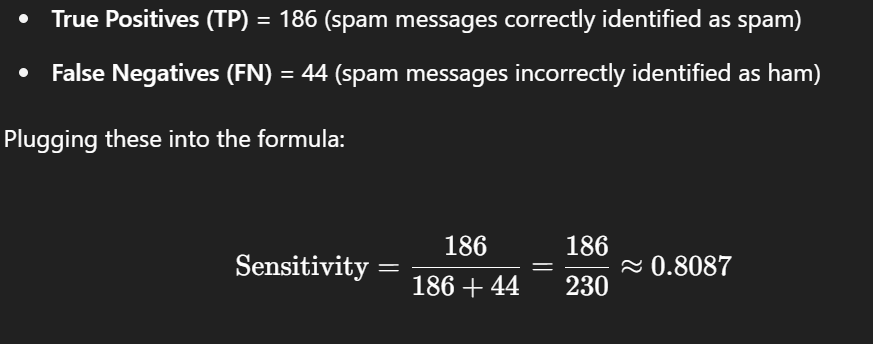

A sensitivity of approximately 80.87% means your model is effective at identifying spam messages but still misses about 19% of them. Depending on your application's requirements, you might consider improving this metric, possibly by adjusting the classification threshold

In [45]:
#specificity/TrueNegativeRate:
# "Out of all the actual Negative instances,
#how many did we correctly predict as negtaive"

specificity = TN / float(TN + FP)

print("specificity",specificity)

specificity 0.9993065187239945


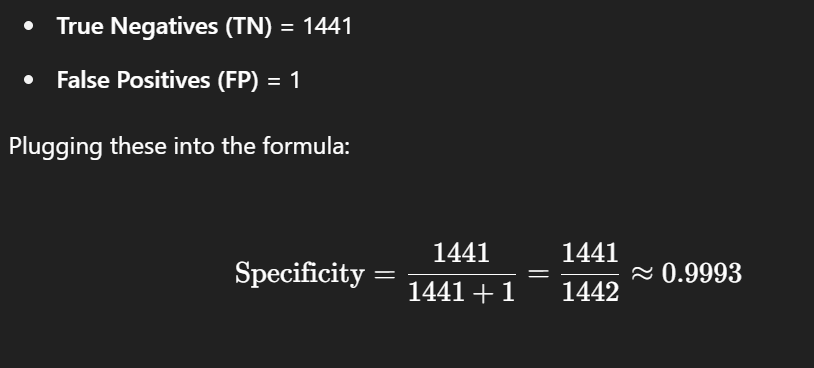

A specificity of approximately 0.9993 (or 99.93%) indicates that your model is highly effective at correctly identifying non-spam (ham) messages. This means that only about 0.07% of actual ham messages are incorrectly classified as spam, which is excellent for minimizing false positives.

In [46]:
precision = TP / float(TP + FP)

print("precision",precision)
print(metrics.precision_score(y_test, y_pred_class))

precision 0.9946524064171123
0.9946524064171123


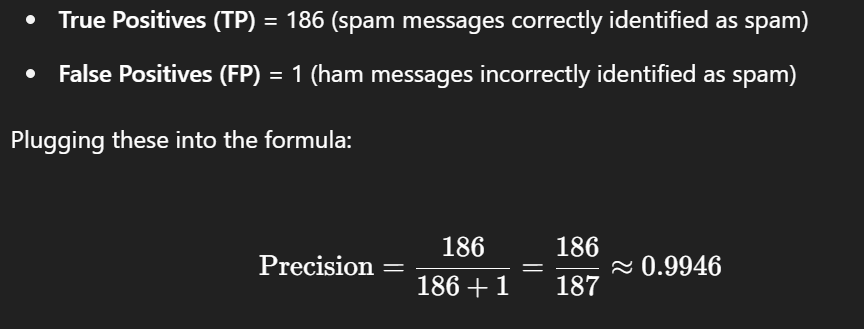

A high precision of 99.46% means your model is very effective at minimizing false positives—i.e., it rarely misclassifies ham messages as spam. This is crucial in applications where false positives can lead to important messages being incorrectly filtered out.​



In [47]:
print("PRECISION SCORE :",metrics.precision_score(y_test, y_pred_class))
print("RECALL SCORE :", metrics.recall_score(y_test, y_pred_class))
print("F1 SCORE :",metrics.f1_score(y_test, y_pred_class))


PRECISION SCORE : 0.9946524064171123
RECALL SCORE : 0.808695652173913
F1 SCORE : 0.8920863309352518


In [49]:
from sklearn.metrics import confusion_matrix as sk_confusion_matrix
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt



false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_pred_proba[:,1])
roc_auc = auc(false_positive_rate, true_positive_rate)

In [51]:
print (roc_auc)

0.9963155038292226


In [52]:
thresholds

array([2.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 9.99999888e-01, 9.99999887e-01,
       9.99996719e-01, 9.99996524e-01, 9.99995820e-01, 9.99994039e-01,
       9.99242905e-01, 9.99184505e-01, 9.98749555e-01, 9.70826104e-01,
       9.69189587e-01, 8.28472697e-01, 8.27026261e-01, 4.16309454e-01,
       2.04962018e-01, 1.51830106e-01, 4.69644707e-02, 3.97237101e-02,
       1.64522550e-03, 1.30134290e-03, 2.98245442e-04, 1.92719205e-04,
       1.48084840e-04, 8.04282878e-05, 6.52483996e-05, 5.84163698e-05,
       5.34250134e-05, 4.40845240e-05, 2.13305977e-05, 1.82950684e-05,
       1.59205760e-05, 1.03642587e-05, 7.81109138e-06, 6.63465360e-06,
       5.57719962e-06, 5.47274810e-06, 4.85186885e-06, 4.54185651e-06,
       2.98863369e-06, 5.28024994e-08, 5.05683449e-08, 3.33048808e-08,
       3.16062039e-08, 2.54967921e-08, 2.41974343e-08, 1.13656995e-08,
      

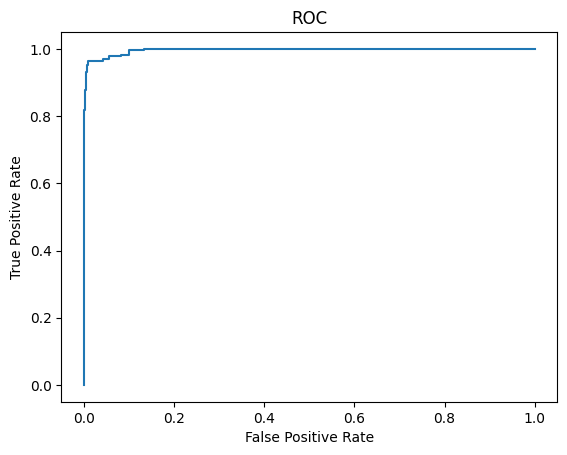

In [53]:
%matplotlib inline  
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC')
plt.plot(false_positive_rate, true_positive_rate)

In [54]:
from sklearn.metrics import classification_report
print(classification_report(y_pred_class,y_test))

              precision    recall  f1-score   support

           0       1.00      0.97      0.98      1485
           1       0.81      0.99      0.89       187

    accuracy                           0.97      1672
   macro avg       0.90      0.98      0.94      1672
weighted avg       0.98      0.97      0.97      1672



In [55]:
#The End....